<a href="https://colab.research.google.com/github/ManasaRPatel/MachineLearning2_LAB/blob/main/kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/ManasaRPatel/MachineLearning2_LAB.git

Cloning into 'MachineLearning2_LAB'...


In [3]:
%cd MachineLearning2_LAB

[Errno 2] No such file or directory: 'MachineLearning2_LAB'
/content/MachineLearning2_LAB


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Load dataset
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Dataset shape: (150, 4)


In [6]:
# Check missing values
print("Missing values:\n", df.isnull().sum())

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("\nData standardized successfully!")

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Data standardized successfully!


In [7]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster assignments:")
display(df.head(10))

Cluster assignments:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


In [8]:
print("Number of flowers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Number of flowers in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


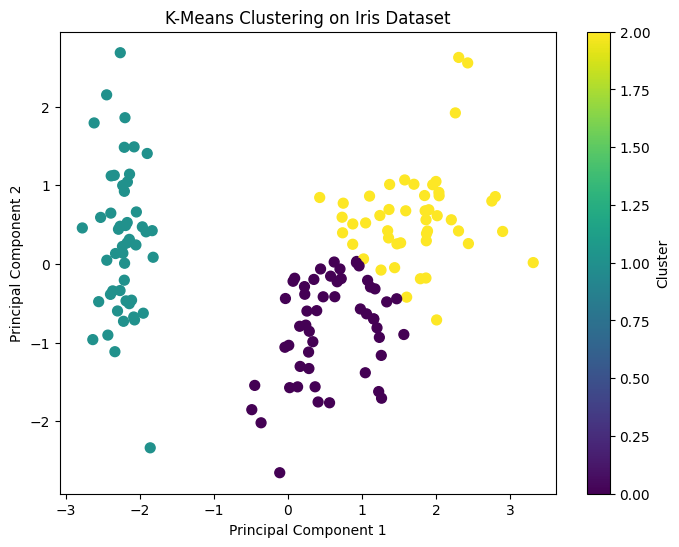

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clustering on Iris Dataset')
plt.colorbar(label='Cluster')
plt.show()

In [10]:
df.to_csv('iris_clustered.csv', index=False)

print("Clustered dataset saved successfully!")

Clustered dataset saved successfully!
